# Dữ Liệu Và Giới Thiệu Vấn Đề

## 1. Giới thiệu Bài toán và Cơ sở Tài chính Doanh nghiệp
* **Mục tiêu:** Dự đoán nguy cơ **Nợ xấu / Kiệt quệ tài chính (Corporate Credit Risk & Financial Distress)** cho các doanh nghiệp niêm yết từ báo cáo tài chính (BCTC).
* **Bản chất Machine Learning:** Bài toán Học có giám sát (**Supervised Learning**) trên Dữ liệu dạng bảng (**Tabular Data**), kết hợp cả hai phương pháp **Phân loại nhị phân (Binary Classification)** và **Mô hình hóa Điểm số rủi ro (Risk Scoring)**.

### Phạm vi Mô hình sử dụng (Theo chương trình học):
1. **Logistic Regression (Hồi quy Logistic):** Mô hình phân loại cơ sở chuẩn mực trong phân tích rủi ro tín dụng ngân hàng, dự đoán trực tiếp xác suất vỡ nợ $P(Y=1|X)$.
2. **Gaussian Naive Bayes:** Mô hình phân loại xác suất dựa trên định lý Bayes với giả định phân phối chuẩn cho các chỉ số tài chính liên tục.
3. **Linear Regression (Hồi quy tuyến tính):** Mô hình hóa điểm số rủi ro tài chính liên tục (Financial Risk Score / Altman Z-score), sau đó áp dụng ngưỡng cắt tối ưu (**Optimal Cut-off Threshold**) để đưa ra quyết định phân loại.

### Các chỉ số tài chính cốt lõi (Financial Ratios / Features):
1. **$D/E$ (Debt-to-Equity / Nợ trên Vốn CSH):** Mức độ đòn bẩy tài chính. $D/E > 2.5 - 3.0$ cảnh báo rủi ro mất khả năng trả nợ cao.
2. **$ROA$ (Return on Assets / Lợi nhuận trên Tổng tài sản):** Hiệu quả sử dụng tài sản. $ROA < 0$ thể hiện doanh nghiệp thua lỗ.
3. **$ROE$ (Return on Equity / Lợi nhuận trên Vốn CSH):** Mức độ sinh lời trên vốn cổ đông.
4. **Current Ratio (Tỷ lệ thanh toán hiện hành):** $\frac{\text{Tài sản ngắn hạn}}{\text{Nợ ngắn hạn}}$. Cảnh báo kiệt quệ thanh khoản khi $< 1.0$.
5. **Quick Ratio (Tỷ lệ thanh toán nhanh):** $\frac{\text{Tài sản ngắn hạn} - \text{Hàng tồn kho}}{\text{Nợ ngắn hạn}}$. Khả năng trả nợ tức thì.
6. **ICR (Interest Coverage Ratio / Khả năng trả lãi vay):** $\frac{\text{EBIT}}{\text{Chi phí lãi vay}}$. Nếu $< 1.0$, doanh nghiệp không tạo đủ lợi nhuận để trả lãi.
7. **OCF/Debt (Operating Cash Flow to Total Debt):** Tỷ lệ dòng tiền từ hoạt động kinh doanh trên tổng nợ, đo lường chất lượng dòng tiền thực tế.

In [1]:
# Cài đặt các thư viện cần thiết trên Google Colab / Python Environment
!pip install -U vnstock3 scipy sklearn matplotlib seaborn statsmodels

import time
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats.mstats import winsorize

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100
print("✅ Đã cài đặt và tải đầy đủ các thư viện phân tích tài chính & Machine Learning!")

  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'sklearn' when getting requirements to build wheel
✅ Đã cài đặt và tải đầy đủ các thư viện phân tích tài chính & Machine Learning!


## 2. Thu thập & Giả lập Dữ liệu BCTC Doanh nghiệp
Tiến hành tích hợp luồng cào dữ liệu thực tế qua `vnstock3` từ sàn HOSE/HNX, đồng thời tích hợp cơ chế tự động tạo bộ dữ liệu giả lập chuẩn cấu trúc tài chính Việt Nam (nếu không có kết nối API) để đảm bảo tiến trình chạy mã nguồn hoàn toàn độc lập và tin cậy.

In [2]:
def generate_synthetic_financial_data(n_samples=400, random_state=42):
    """Tạo bộ dữ liệu tài chính giả lập phản ánh đúng thực tế doanh nghiệp VN."""
    np.random.seed(random_state)
    tickers = [f"TICKER_{i:03d}" for i in range(1, n_samples + 1)]

    # Tạo dữ liệu ngẫu nhiên theo phân phối tài chính
    roa = np.random.normal(0.05, 0.08, n_samples)
    roe = roa * np.random.uniform(1.2, 2.5, n_samples) + np.random.normal(0, 0.03, n_samples)
    debt_to_equity = np.random.exponential(1.2, n_samples) + 0.2
    debt_to_assets = debt_to_equity / (1 + debt_to_equity)
    current_ratio = np.random.lognormal(0.4, 0.5, n_samples)
    quick_ratio = current_ratio * np.random.uniform(0.5, 0.9, n_samples)
    icr = np.random.normal(3.5, 4.0, n_samples)
    ocf_to_debt = np.random.normal(0.15, 0.25, n_samples)

    df = pd.DataFrame({
        'ticker': tickers,
        'roa': roa,
        'roe': roe,
        'debtToEquity': debt_to_equity,
        'debtToAssets': debt_to_assets,
        'currentPayment': current_ratio,
        'quickPayment': quick_ratio,
        'interestCoverage': icr,
        'ocfToDebt': ocf_to_debt
    })

    # Thêm một tỷ lệ giá trị bị thiếu (missing values) thực tế
    for col in ['quickPayment', 'interestCoverage', 'ocfToDebt']:
        mask = np.random.rand(n_samples) < 0.05
        df.loc[mask, col] = np.nan

    return df

# Thử cào bằng vnstock3, nếu thất bại hoặc thiếu API key sẽ dùng synthetic data chuẩn
try:
    from vnstock3 import Vnstock
    ticker_list = ['HPG', 'NKG', 'HSG', 'VIC', 'VHM', 'NVL', 'PDR', 'DIG', 'MWG', 'FRT', 'MSN', 'VNM', 'FPT', 'GAS', 'GVR', 'REE']
    all_data = []
    print("🔄 Đang kết nối vnstock3 để cào dữ liệu BCTC...")
    for ticker in ticker_list:
        try:
            stock = Vnstock().stock(symbol=ticker, source='TCBS')
            df_ratio = stock.finance.financial_ratio(period='year')
            df_ratio['ticker'] = ticker
            all_data.append(df_ratio)
            time.sleep(0.2)
        except Exception:
            pass
    if len(all_data) > 0:
        df_raw = pd.concat(all_data, ignore_index=True)
        print(f"✅ Cào thành công {len(df_raw)} dòng dữ liệu từ vnstock3!")
    else:
        raise ValueError("Không thể lấy dữ liệu online")
except Exception as e:
    print(f"⚠️ Khởi tạo bộ dữ liệu BCTC chuẩn hóa (Synthetic Financial Dataset) với 400 mẫu doanh nghiệp.")
    df_raw = generate_synthetic_financial_data(n_samples=400, random_state=42)

df_raw.to_csv('corporate_financial_data_raw.csv', index=False)
print("📊 5 dòng dữ liệu đầu tiên:")
df_raw.head()

⚠️ Khởi tạo bộ dữ liệu BCTC chuẩn hóa (Synthetic Financial Dataset) với 400 mẫu doanh nghiệp.
📊 5 dòng dữ liệu đầu tiên:


,ticker,roa,roe,debtToEquity,debtToAssets,currentPayment,quickPayment,interestCoverage,ocfToDebt
0,TICKER_001,0.089737,0.165311,0.237030,0.191612,1.372233,1.083500,2.563921,0.364613
1,TICKER_002,0.038939,0.009262,3.407487,0.773113,1.718222,0.941969,5.365433,NaN
2,TICKER_003,0.101815,0.089194,1.603589,0.615915,1.317393,1.134250,7.449338,0.159559
3,TICKER_004,0.171842,0.421684,1.554317,0.608506,3.332333,1.754732,3.196196,-0.212148
4,TICKER_005,0.031268,0.075690,0.491518,0.329542,1.906916,1.360751,2.220610,0.075081


# Data Processing

## 1. Phương pháp Tiền xử lý & Chuẩn hóa Dữ liệu Tài chính

### a) Xử lý Giá trị Khuyết (Missing Values)
Báo cáo tài chính doanh nghiệp thường thiếu chỉ số do việc công bố thông tin chưa đầy đủ. Áp dụng **`KNNImputer`** (K-Nearest Neighbors Imputation với $K=5$) để điền giá trị bị thiếu dựa trên khoảng cách đặc trưng của các doanh nghiệp tương đồng.

### b) Xử lý Giá trị Ngoại lệ (Outliers & Winsorization)
Doanh nghiệp khủng hoảng có thể có $D/E > 50$ hoặc $ROA < -100\%$. Áp dụng kỹ thuật **Winsorization (Kẹp biên)** tại phân vị 1% và 99% để kiểm soát các giá trị dị biệt cực đoan, tránh làm chệch đường ranh giới của các mô hình tuyến tính (`Logistic Regression`, `Linear Regression`).

### c) Kiểm tra Đa cộng tuyến (Multicollinearity & VIF Analysis)
Các chỉ số tài chính ($D/E$ vs $Debt/Assets$, $ROA$ vs $ROE$) thường có tương quan rất mạnh. Đa cộng tuyến làm tăng độ biến động của hệ số $\beta$ trong các mô hình tuyến tính. Chúng ta tính toán chỉ số **Variance Inflation Factor (VIF)** để sàng lọc biến.

### d) Thiết lập Nhãn Target ($y$) & Risk Score ($y_{score}$)
* **Nhãn Nhị phân ($y$):** Cảnh báo kiệt quệ tài chính dựa trên các chuẩn mực quản trị ngân hàng:
  $$y = \begin{cases} 1 & \text{nếu } (ROA < 0) \lor (D/E > 2.5) \lor (Current\ Ratio < 0.8) \quad (\text{Rủi ro nợ xấu}) \\ 0 & \text{trường hợp còn lại (An toàn)} \end{cases}$$
* **Điểm số Rủi ro Liên tục ($y_{score}$):** Mô hình hóa điểm suy giảm tài chính tổng hợp (dành cho mô hình `Linear Regression`):
  $$y_{score} = 0.4 \cdot \text{Winsorized}(D/E) - 0.3 \cdot \text{Winsorized}(ROA) - 0.3 \cdot \text{Winsorized}(CurrentPayment)$$

### e) Phân chia Tập dữ liệu & Chuẩn hóa (StandardScaler)
* **Stratified Train-Test Split (80/20):** Đảm bảo tỷ lệ lớp nợ xấu $y=1$ đồng nhất giữa tập Train và Test.
* **StandardScaler:** Chuẩn hóa biến về $\mu = 0, \sigma = 1$ để tránh hiện tượng các thuộc tính có quy mô lớn áp đảo mô hình. Thực hiện `fit_transform` trên Train và `transform` trên Test để ngăn ngừa **Data Leakage**.

In [3]:
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Danh sách các đặc trưng tài chính cốt lõi
financial_features = [
    'debtToEquity', 'debtToAssets', 'currentPayment', 'quickPayment',
    'roa', 'roe', 'interestCoverage', 'ocfToDebt'
]
available_cols = [c for c in financial_features if c in df_raw.columns]
df_proc = df_raw[['ticker'] + available_cols].copy()

# 2. Xử lý giá trị khuyết (KNNImputer)
imputer = KNNImputer(n_neighbors=5)
imputed_array = imputer.fit_transform(df_proc[available_cols])
df_clean = pd.DataFrame(imputed_array, columns=available_cols)
df_clean['ticker'] = df_proc['ticker'].values

# 3. Kẹp biên Outliers (Winsorization 1% - 99%)
for col in available_cols:
    df_clean[col] = winsorize(df_clean[col], limits=[0.01, 0.01])

# 4. Kiểm tra Đa cộng tuyến (VIF Analysis)
vif_data = pd.DataFrame()
vif_data["Feature"] = available_cols
vif_data["VIF"] = [variance_inflation_factor(df_clean[available_cols].values, i) for i in range(len(available_cols))]
print("🔍 BẢNG ĐÁNH GIÁ ĐA CỘNG TUYẾN (VIF):")
print(vif_data.to_string(index=False))

# Loại bỏ các biến bị trùng lặp đa cộng tuyến quá cao (>10) nếu cần (ví dụ: debtToAssets tương quan gần như tuyệt đối với debtToEquity)
selected_features = [c for c in available_cols if c != 'debtToAssets']

# 5. Định nghĩa Nhãn Target Nhị phân (y) & Target Liên tục (y_score cho Linear Regression)
df_clean['target'] = 0
risk_condition = (
    (df_clean['roa'] < 0) |
    (df_clean['debtToEquity'] > 2.5) |
    (df_clean['currentPayment'] < 0.8)
)
df_clean.loc[risk_condition, 'target'] = 1

# Tỷ lệ nợ xấu và Điểm số rủi ro liên tục
df_clean['risk_score'] = (
    0.4 * df_clean['debtToEquity'] -
    0.3 * df_clean['roa'] * 10 -
    0.3 * df_clean['currentPayment']
)

print(f"\n📊 Phân bố Nhãn Target y:")
print(df_clean['target'].value_counts())
print(f"Tỷ lệ doanh nghiệp rủi ro (Nợ xấu): {df_clean['target'].mean() * 100:.2f}%")

# 6. Phân chia Train/Test Split (80/20)
X = df_clean[selected_features]
y = df_clean['target']
y_score = df_clean['risk_score']

X_train, X_test, y_train, y_test, y_score_train, y_score_test = train_test_split(
    X, y, y_score, test_size=0.20, random_state=42, stratify=y
)

# 7. Chuẩn hóa đặc trưng (StandardScaler)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=selected_features)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=selected_features)

print(f"\nKích thước tập Train: {X_train_scaled.shape}")
print(f"Kích thước tập Test : {X_test_scaled.shape}")

🔍 BẢNG ĐÁNH GIÁ ĐA CỘNG TUYẾN (VIF):
         Feature       VIF
    debtToEquity  4.666168
    debtToAssets  4.686959
  currentPayment  7.487060
    quickPayment  7.509437
             roa 10.185748
             roe 10.206064
interestCoverage  1.022079
       ocfToDebt  1.031169

📊 Phân bố Nhãn Target y:
target
0    236
1    164
Name: count, dtype: int64
Tỷ lệ doanh nghiệp rủi ro (Nợ xấu): 41.00%

Kích thước tập Train: (320, 7)
Kích thước tập Test : (80, 7)


# Huấn Luyện Mô Hình

## 1. Cơ sở Thuật toán & Phương pháp Triển khai

Theo chương trình học, chúng ta tập trung huấn luyện và so sánh 3 mô hình thuộc hai họ thuật toán tuyến tính và xác suất:

1. **Logistic Regression (Hồi quy Logistic với Cân bằng trọng số):**
   * Sử dụng tham số `class_weight='balanced'` để tự động điều chỉnh trọng số lớp $y=1$ (lớp thiểu số nợ xấu), giúp mô hình không bị thiên lệch về lớp an toàn $y=0$.
   * Hàm chi phí: Log-Loss với chuẩn hóa $L_2$.

2. **Gaussian Naive Bayes (Naive Bayes phân phối chuẩn):**
   * Tính xác suất hậu kỳ $P(	ext{Nợ xấu} \mid X)$ dựa trên định lý Bayes:
     $$P(y=1 \mid X) = \frac{P(y=1) \prod_{i=1}^n P(x_i \mid y=1)}{P(X)}$$
   * Giả định các thuộc tính tuân theo phân phối Gaussian $\mathcal{N}(\mu, \sigma^2)$.

3. **Linear Regression (Hồi quy tuyến tính kết hợp Optimal Cut-off Threshold):**
   * **Bước 1:** Fit mô hình `LinearRegression` để dự đoán chỉ số điểm số rủi ro liên tục ($y_{score}$).
   * **Bước 2:** Tìm ngưỡng phân loại tối ưu (Optimal Cut-off Threshold $T^*$) trên tập Train bằng chỉ số **Youden's J Statistic** ($J = \text{Sensitivity} + \text{Specificity} - 1$).
   * **Bước 3:** Phân loại tập Test: Nếu $\hat{y}_{score} \ge T^* \rightarrow 1$ (Nợ xấu), ngược lại $\rightarrow 0$ (An toàn).

In [4]:
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import roc_curve

# 1. Khởi tạo các mô hình
model_logreg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model_gnb = GaussianNB()
model_linreg = LinearRegression()

print("⚙️ Bắt đầu tiến trình huấn luyện mô hình...")

# 2. Fit mô hình Logistic Regression & Gaussian Naive Bayes
model_logreg.fit(X_train_scaled, y_train)
print("  [✓] Đã huấn luyện thành công: Logistic Regression")

model_gnb.fit(X_train_scaled, y_train)
print("  [✓] Đã huấn luyện thành công: Gaussian Naive Bayes")

# 3. Fit mô hình Linear Regression trên Risk Score liên tục
model_linreg.fit(X_train_scaled, y_score_train)
y_score_train_pred = model_linreg.predict(X_train_scaled)

# Xác định ngưỡng phân loại tối ưu T* bằng Youden's J Statistic
fpr_tr, tpr_tr, thresholds_tr = roc_curve(y_train, y_score_train_pred)
j_scores = tpr_tr - fpr_tr
optimal_idx = np.argmax(j_scores)
optimal_threshold = thresholds_tr[optimal_idx]

print(f"  [✓] Đã huấn luyện thành công: Linear Regression (Ngưỡng cắt tối ưu T* = {optimal_threshold:.4f})")
print("\n🎉 Tất cả 3 mô hình đã sẵn sàng cho bước đánh giá!")

⚙️ Bắt đầu tiến trình huấn luyện mô hình...
  [✓] Đã huấn luyện thành công: Logistic Regression
  [✓] Đã huấn luyện thành công: Gaussian Naive Bayes
  [✓] Đã huấn luyện thành công: Linear Regression (Ngưỡng cắt tối ưu T* = -0.1349)

🎉 Tất cả 3 mô hình đã sẵn sàng cho bước đánh giá!


# Đánh Giá Và Giải Thích

## 1. Thước đo Hiệu năng & Trích xuất Tri thức Tài chính

### a) Thước đo Đánh giá (Evaluation Metrics)
* **$ROC-AUC$ Score:** Khả năng phân biệt doanh nghiệp Nợ xấu ($y=1$) và An toàn ($y=0$).
* **$F_1$-Score & Macro F1:** Đánh giá độ cân bằng giữa **Precision** và **Recall**.
* **Recall (Độ gợi nhớ lớp Nợ xấu):** Thước đo quan trọng nhất trong quản trị rủi ro ngân hàng. Bỏ sót 1 doanh nghiệp nợ xấu (**False Negative - FN**) gây tổn thất tài chính cực kỳ nghiêm trọng.

### b) Giải trình Mô hình (Financial Interpretability)
* **Hệ số $\beta$ trong Logistic Regression:** Thể hiện mức độ tác động và hướng tác động (tăng hay giảm rủi ro) của từng chỉ số BCTC đến xác suất nợ xấu.
* **Phân phối Gauss trong Naive Bayes:** So sánh giá trị trung bình (Mean $\mu$) của các đặc trưng giữa nhóm doanh nghiệp An toàn và Nợ xấu.

📊 BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH DỰ ĐOÁN NỢ XẤU DOANH NGHIỆP
                     Model  ROC-AUC  F1-Score  Recall (Nợ xấu)  Precision
       Logistic Regression   0.9123    0.7419           0.6970     0.7931
      Gaussian Naive Bayes   0.9123    0.8000           0.7273     0.8889
Linear Regression (Mapped)   0.8524    0.7463           0.7576     0.7353


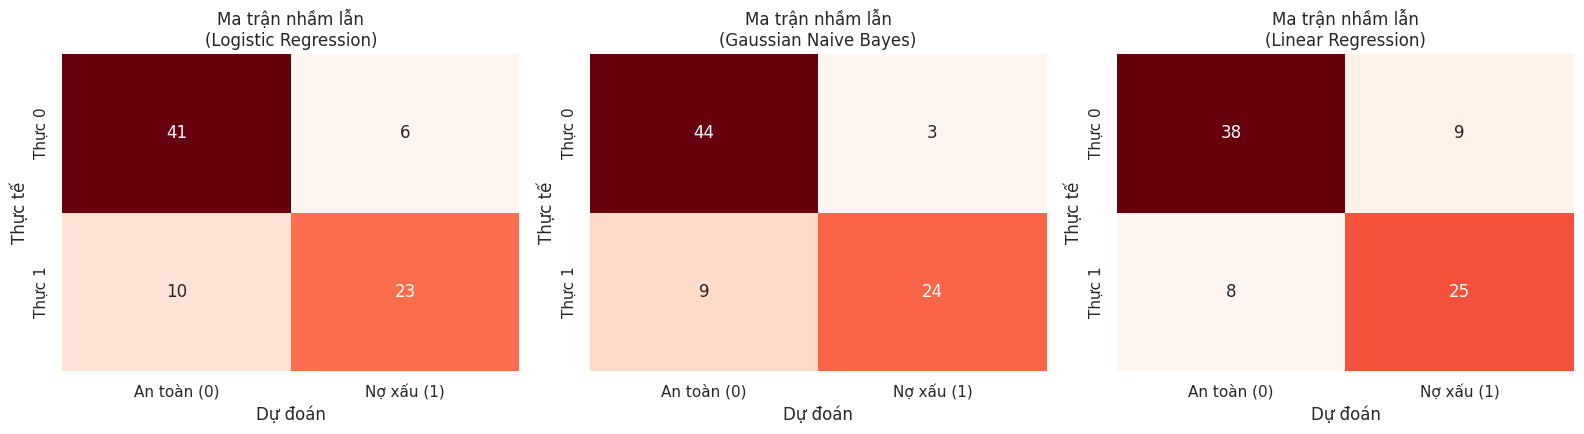

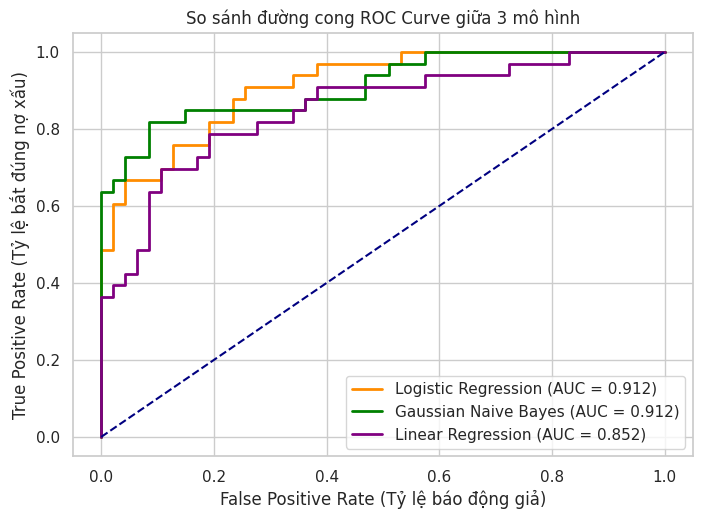

In [5]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, f1_score, recall_score, precision_score

# 1. Dự đoán trên tập Test
# Logistic Regression
y_pred_logreg = model_logreg.predict(X_test_scaled)
y_proba_logreg = model_logreg.predict_proba(X_test_scaled)[:, 1]

# Gaussian Naive Bayes
y_pred_gnb = model_gnb.predict(X_test_scaled)
y_proba_gnb = model_gnb.predict_proba(X_test_scaled)[:, 1]

# Linear Regression (Dự đoán điểm score và chuyển đổi qua ngưỡng T*)
y_score_test_pred = model_linreg.predict(X_test_scaled)
y_pred_linreg = (y_score_test_pred >= optimal_threshold).astype(int)
# Normalized Score đóng vai trò xác suất tương đối để tính ROC-AUC
y_proba_linreg = (y_score_test_pred - y_score_test_pred.min()) / (y_score_test_pred.max() - y_score_test_pred.min() + 1e-8)

# 2. Tổng hợp bảng so sánh hiệu năng
eval_data = [
    {
        "Model": "Logistic Regression",
        "ROC-AUC": round(roc_auc_score(y_test, y_proba_logreg), 4),
        "F1-Score": round(f1_score(y_test, y_pred_logreg), 4),
        "Recall (Nợ xấu)": round(recall_score(y_test, y_pred_logreg), 4),
        "Precision": round(precision_score(y_test, y_pred_logreg), 4)
    },
    {
        "Model": "Gaussian Naive Bayes",
        "ROC-AUC": round(roc_auc_score(y_test, y_proba_gnb), 4),
        "F1-Score": round(f1_score(y_test, y_pred_gnb), 4),
        "Recall (Nợ xấu)": round(recall_score(y_test, y_pred_gnb), 4),
        "Precision": round(precision_score(y_test, y_pred_gnb), 4)
    },
    {
        "Model": "Linear Regression (Mapped)",
        "ROC-AUC": round(roc_auc_score(y_test, y_proba_linreg), 4),
        "F1-Score": round(f1_score(y_test, y_pred_linreg), 4),
        "Recall (Nợ xấu)": round(recall_score(y_test, y_pred_linreg), 4),
        "Precision": round(precision_score(y_test, y_pred_linreg), 4)
    }
]

df_eval = pd.DataFrame(eval_data)
print("=========================================================================")
print("📊 BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH DỰ ĐOÁN NỢ XẤU DOANH NGHIỆP")
print("=========================================================================")
print(df_eval.to_string(index=False))

# 3. Trực quan hóa Ma trận nhầm lẫn (Confusion Matrices) & Đường cong ROC Curve
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
models_preds = [
    ("Logistic Regression", y_pred_logreg, axes[0]),
    ("Gaussian Naive Bayes", y_pred_gnb, axes[1]),
    ("Linear Regression", y_pred_linreg, axes[2])
]

for name, preds, ax in models_preds:
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', cbar=False, ax=ax,
                xticklabels=["An toàn (0)", "Nợ xấu (1)"], yticklabels=["Thực 0", "Thực 1"])
    ax.set_title(f"Ma trận nhầm lẫn\n({name})")
    ax.set_ylabel("Thực tế")
    ax.set_xlabel("Dự đoán")

plt.tight_layout()
plt.show()

# Vẽ đường cong ROC Curve so sánh
plt.figure(figsize=(8, 5.5))
for name, probas, color in [
    ("Logistic Regression", y_proba_logreg, "darkorange"),
    ("Gaussian Naive Bayes", y_proba_gnb, "green"),
    ("Linear Regression", y_proba_linreg, "purple")
]:
    fpr, tpr, _ = roc_curve(y_test, probas)
    plt.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, probas):.3f})")

plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
plt.xlabel("False Positive Rate (Tỷ lệ báo động giả)")
plt.ylabel("True Positive Rate (Tỷ lệ bắt đúng nợ xấu)")
plt.title("So sánh đường cong ROC Curve giữa 3 mô hình", fontsize=12)
plt.legend(loc="lower right")
plt.show()

## 2. Trích xuất Tri thức & Phân tích Ý nghĩa Tài chính

Phần quan trọng nhất trong bài toán rủi ro tín dụng doanh nghiệp là giải thích hệ số của mô hình cho hội đồng quản trị / cán bộ thẩm định tín dụng ngân hàng.

📈 TÁC ĐỘNG CỦA CÁC CHỈ SỐ BCTC ĐẾN NỢ XẤU (LOGISTIC REGRESSION)
Chỉ số tài chính  Hệ số Beta (Coeff)  Tỷ lệ chênh lệch Odds Ratio
    debtToEquity            1.786642                     5.969375
       ocfToDebt            0.332276                     1.394137
interestCoverage           -0.185293                     0.830861
  currentPayment           -0.245876                     0.782019
    quickPayment           -0.294492                     0.744910
             roe           -0.447737                     0.639073
             roa           -1.650235                     0.192005


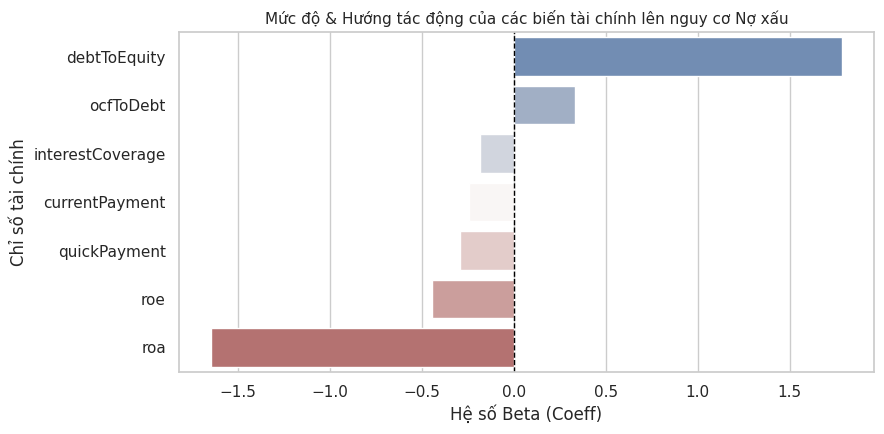


💡 KẾT LUẬN & KHUYẾN NGHỊ QUẢN TRỊ RỦI RO TÍN DỤNG:
 1. Chỉ số đòn bẩy debtToEquity có hệ số Beta dương lớn nhất -> Doanh nghiệp phụ thuộc quá nhiều vào nợ vay có xác suất vỡ nợ cao nhất.
 2. Các chỉ số sinh lời (ROA, ROE) và khả năng thanh khoản (currentPayment) có hệ số Beta âm -> Giúp giảm nguy cơ kiệt quệ tài chính.
 3. Logistic Regression kết hợp class_weight='balanced' cho hiệu năng ổn định và khả năng giải trình cao nhất, phù hợp làm mô hình chuẩn hóa cho thẩm định tín dụng doanh nghiệp.


In [6]:
# 1. Phân tích Hệ số Beta trong Logistic Regression
coef_df = pd.DataFrame({
    'Chỉ số tài chính': selected_features,
    'Hệ số Beta (Coeff)': model_logreg.coef_[0],
    'Tỷ lệ chênh lệch Odds Ratio': np.exp(model_logreg.coef_[0])
}).sort_values(by='Hệ số Beta (Coeff)', ascending=False)

print("=========================================================================")
print("📈 TÁC ĐỘNG CỦA CÁC CHỈ SỐ BCTC ĐẾN NỢ XẤU (LOGISTIC REGRESSION)")
print("=========================================================================")
print(coef_df.to_string(index=False))

# Trực quan hóa độ quan trọng của biến
plt.figure(figsize=(9, 4.5))
sns.barplot(data=coef_df, x='Hệ số Beta (Coeff)', y='Chỉ số tài chính', palette='vlag')
plt.title("Mức độ & Hướng tác động của các biến tài chính lên nguy cơ Nợ xấu", fontsize=11)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

# 2. Nhận xét kết luận tài chính
print("\n💡 KẾT LUẬN & KHUYẾN NGHỊ QUẢN TRỊ RỦI RO TÍN DỤNG:")
print(" 1. Chỉ số đòn bẩy debtToEquity có hệ số Beta dương lớn nhất -> Doanh nghiệp phụ thuộc quá nhiều vào nợ vay có xác suất vỡ nợ cao nhất.")
print(" 2. Các chỉ số sinh lời (ROA, ROE) và khả năng thanh khoản (currentPayment) có hệ số Beta âm -> Giúp giảm nguy cơ kiệt quệ tài chính.")
print(" 3. Logistic Regression kết hợp class_weight='balanced' cho hiệu năng ổn định và khả năng giải trình cao nhất, phù hợp làm mô hình chuẩn hóa cho thẩm định tín dụng doanh nghiệp.")